In [3]:
import sys
import os
import math
import numpy as np
import scipy as sp
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt, colors, patches

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA


from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [4]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/utils/train_utils.py'>

In [5]:
# read_ids = list(range(0, 12+1))
read_ids = [0, 2, 3, 6, 8, 9]
plot_id = 0

dims = 3

In [6]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [7]:
# prep
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(data=trace.values[1:, :], columns=trace.columns) for trace in traces]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

states = [pd.DataFrame(data=state.values[1:, :], columns=state.columns) for state in states]

In [8]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces,
												 n_pc=dims)

In [9]:
traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

# traces_residuals = list()
# for file_id in file_ids:
# 	traces_residuals.append(pd.read_csv(f'./out/residuals/{file_id}_{filenames[file_ids.index(file_id)]}.csv', index_col=0))

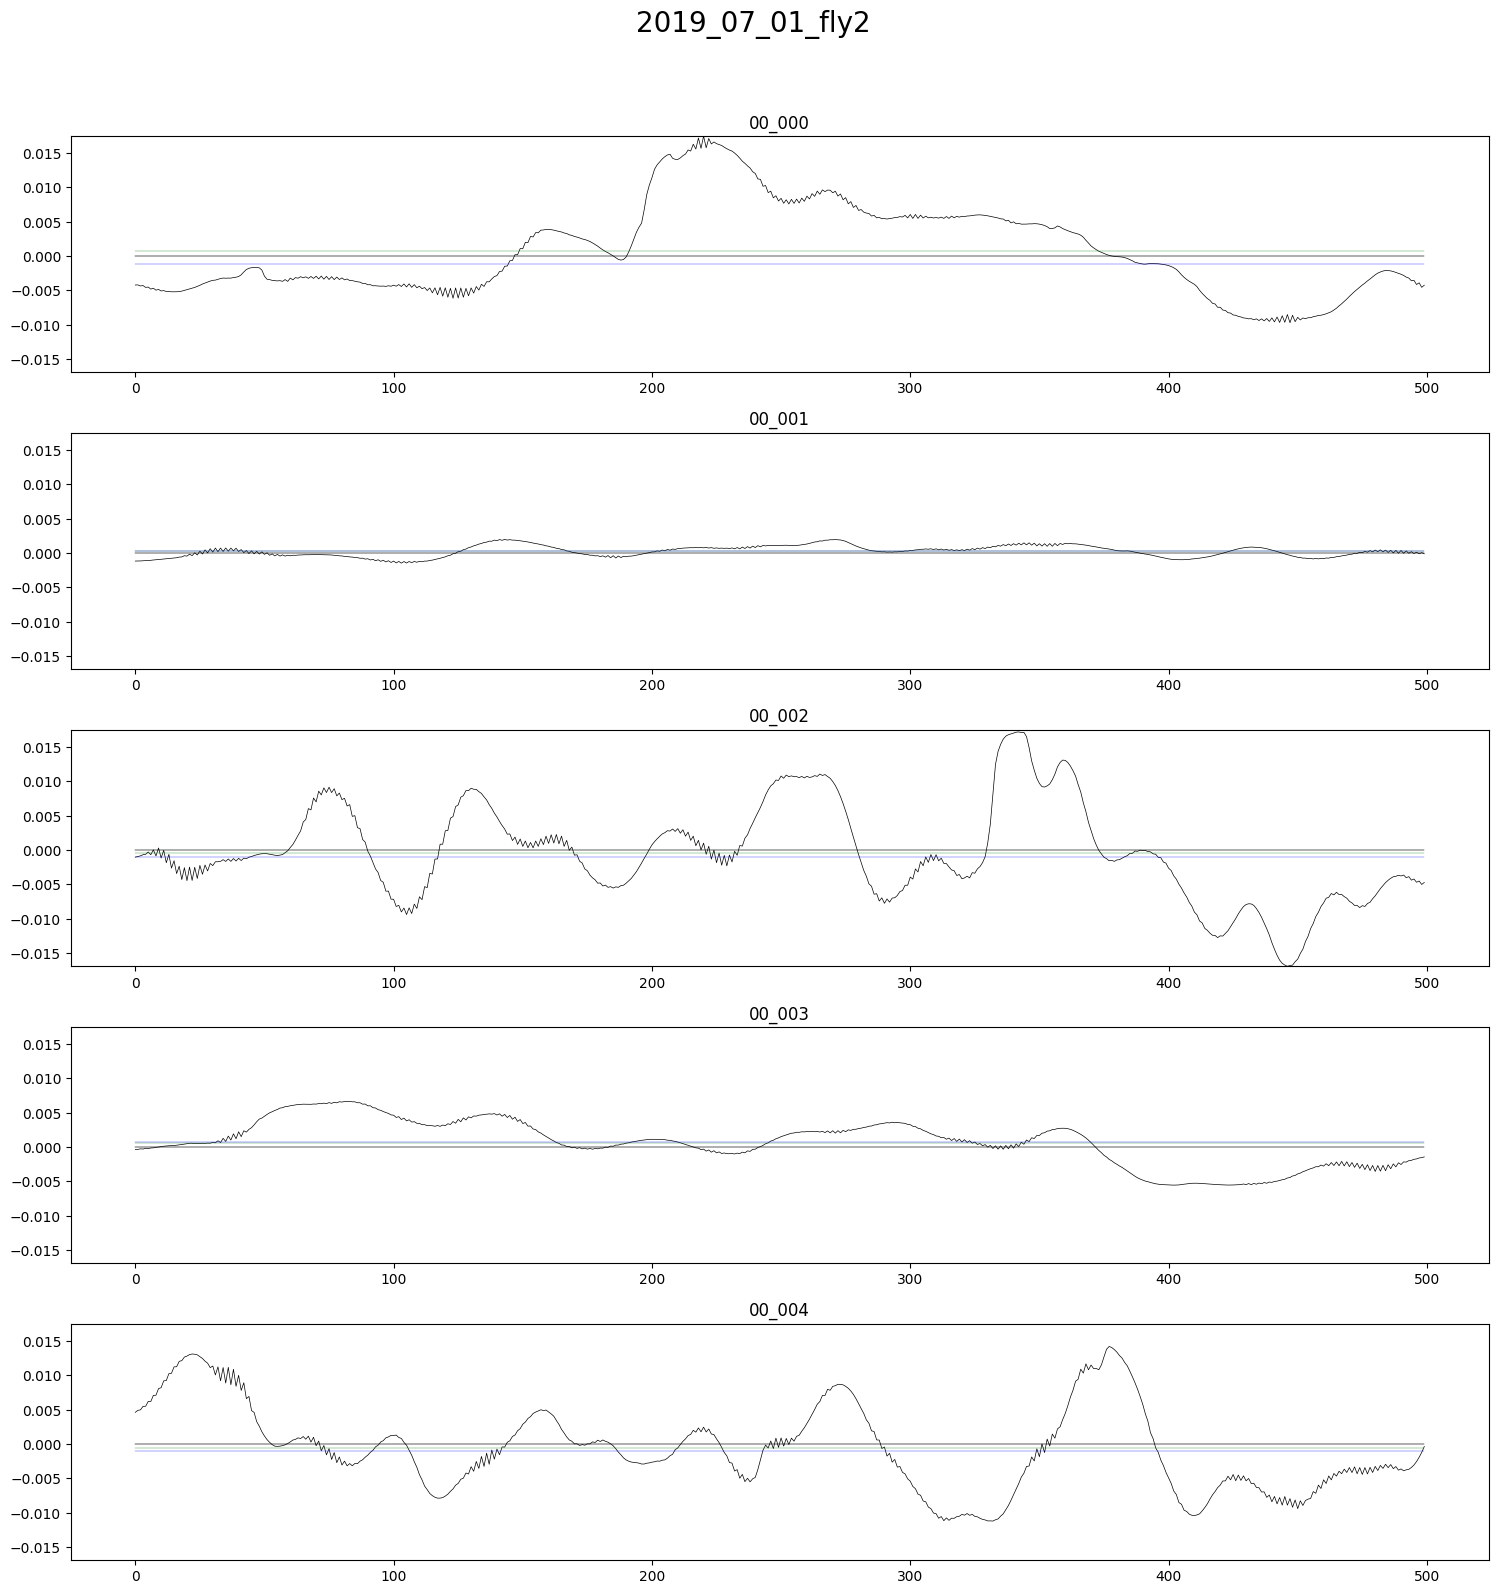

In [11]:
plot_utils.plot_traces_singular(f'{filenames[file_ids.index(plot_id)]}',
								traces_residuals[file_ids.index(plot_id)].iloc[:500, :5],
								mean=True, median=True,
								plots_per_row=1, top_space=1, ylimits=None)

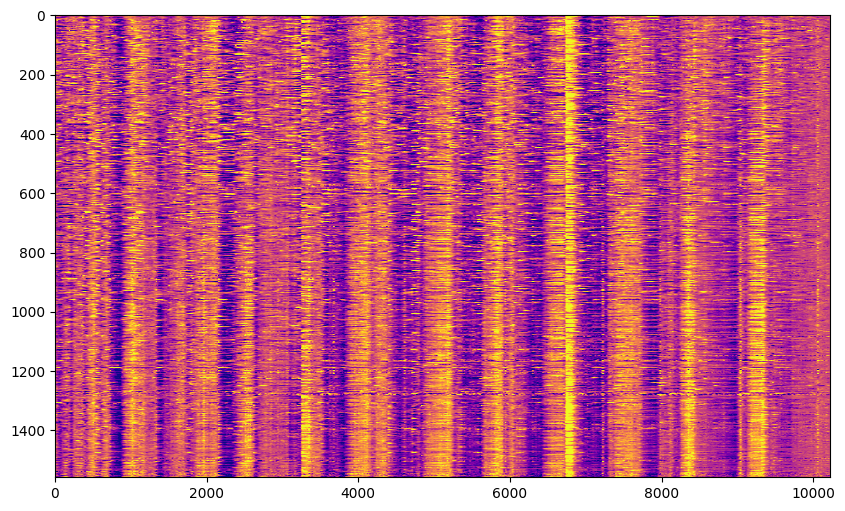

In [12]:
plt.figure(figsize=(10, 6))
plt.imshow(np.clip(traces[file_ids.index(plot_id)].values.T, -0.015, 0.015), aspect='auto', interpolation='nearest', cmap='plasma')

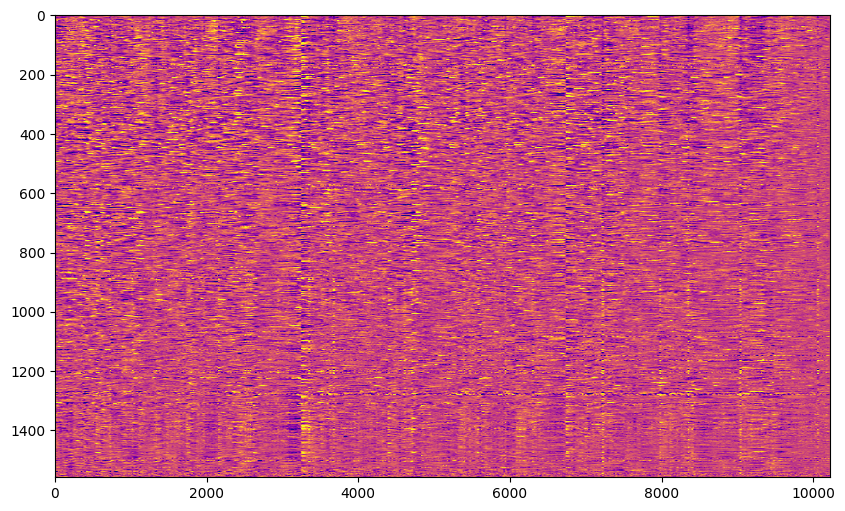

In [13]:
plt.figure(figsize=(10, 6))
plt.imshow(np.clip(traces_residuals[file_ids.index(plot_id)].values.T, -0.015, 0.015), aspect='auto', interpolation='nearest', cmap='plasma')

In [14]:
# markers z-scored
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]

# markers difference z-scored
markers_diff = [pd.DataFrame(data=marker.values[1:, :] - marker.values[:-1, :], columns=marker.columns) for marker in markers]
markers_diff_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers_diff
]

# regression

In [24]:
def r2_score_oos(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2)
	ss_tot = np.sum((y_eval - baseline) ** 2)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

def r2_score_oos_single(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2, axis=0)
	ss_tot = np.sum((y_eval - baseline) ** 2, axis=0)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

In [30]:
traces_residuals_pred = list()
r2s = list()

for i, markers_version in enumerate([markers_zs, markers_diff_zs]):
	marker = markers_version[file_ids.index(plot_id)]
	if i == 0:
		marker = marker.iloc[1:]
	trace = traces_residuals[file_ids.index(plot_id)]

	X_train, X_test, y_train, y_test = train_test_split(
		marker.values, trace.values, test_size=0.2, random_state=42
	)

	lr = LinearRegression()
	lr.fit(X_train, y_train)

	y_test_pred = lr.predict(X_test)
	traces_residuals_pred.append(pd.DataFrame(data=lr.predict(marker.values), columns=trace.columns))

	r2 = r2_score_oos(y_test, y_test_pred, y_train.mean(axis=0))
	mse = mean_squared_error(y_test, y_test_pred)

	r2_single = r2_score_oos_single(y_test, y_test_pred, y_train.mean(axis=0)).reshape(-1, 1).T
	r2s.append(pd.DataFrame(data=r2_single, columns=trace.columns))

	print(i, "R²:", r2)
	print(i, "MSE:", mse)

0 R²: 0.03845029818240209
0 MSE: 1.5758220507141952e-05
1 R²: -0.0036077967499617003
1 MSE: 1.644748361314853e-05


In [62]:
r2_indices = [np.argsort(r2s[0].values).reshape(1559,), np.argsort(r2s[1].values).reshape(1559,)]

In [63]:
print(r2s[0].iloc[:, r2_indices[0][-5:]])
print(r2s[1].iloc[:, r2_indices[1][-5:]])

     00_789   00_1071    00_907    00_568    00_521
0  0.121515  0.124105  0.143598  0.146623  0.146958
    00_1325   00_1097   00_1507    00_120    00_711
0 -0.000693 -0.000615 -0.000152 -0.000083  0.000186


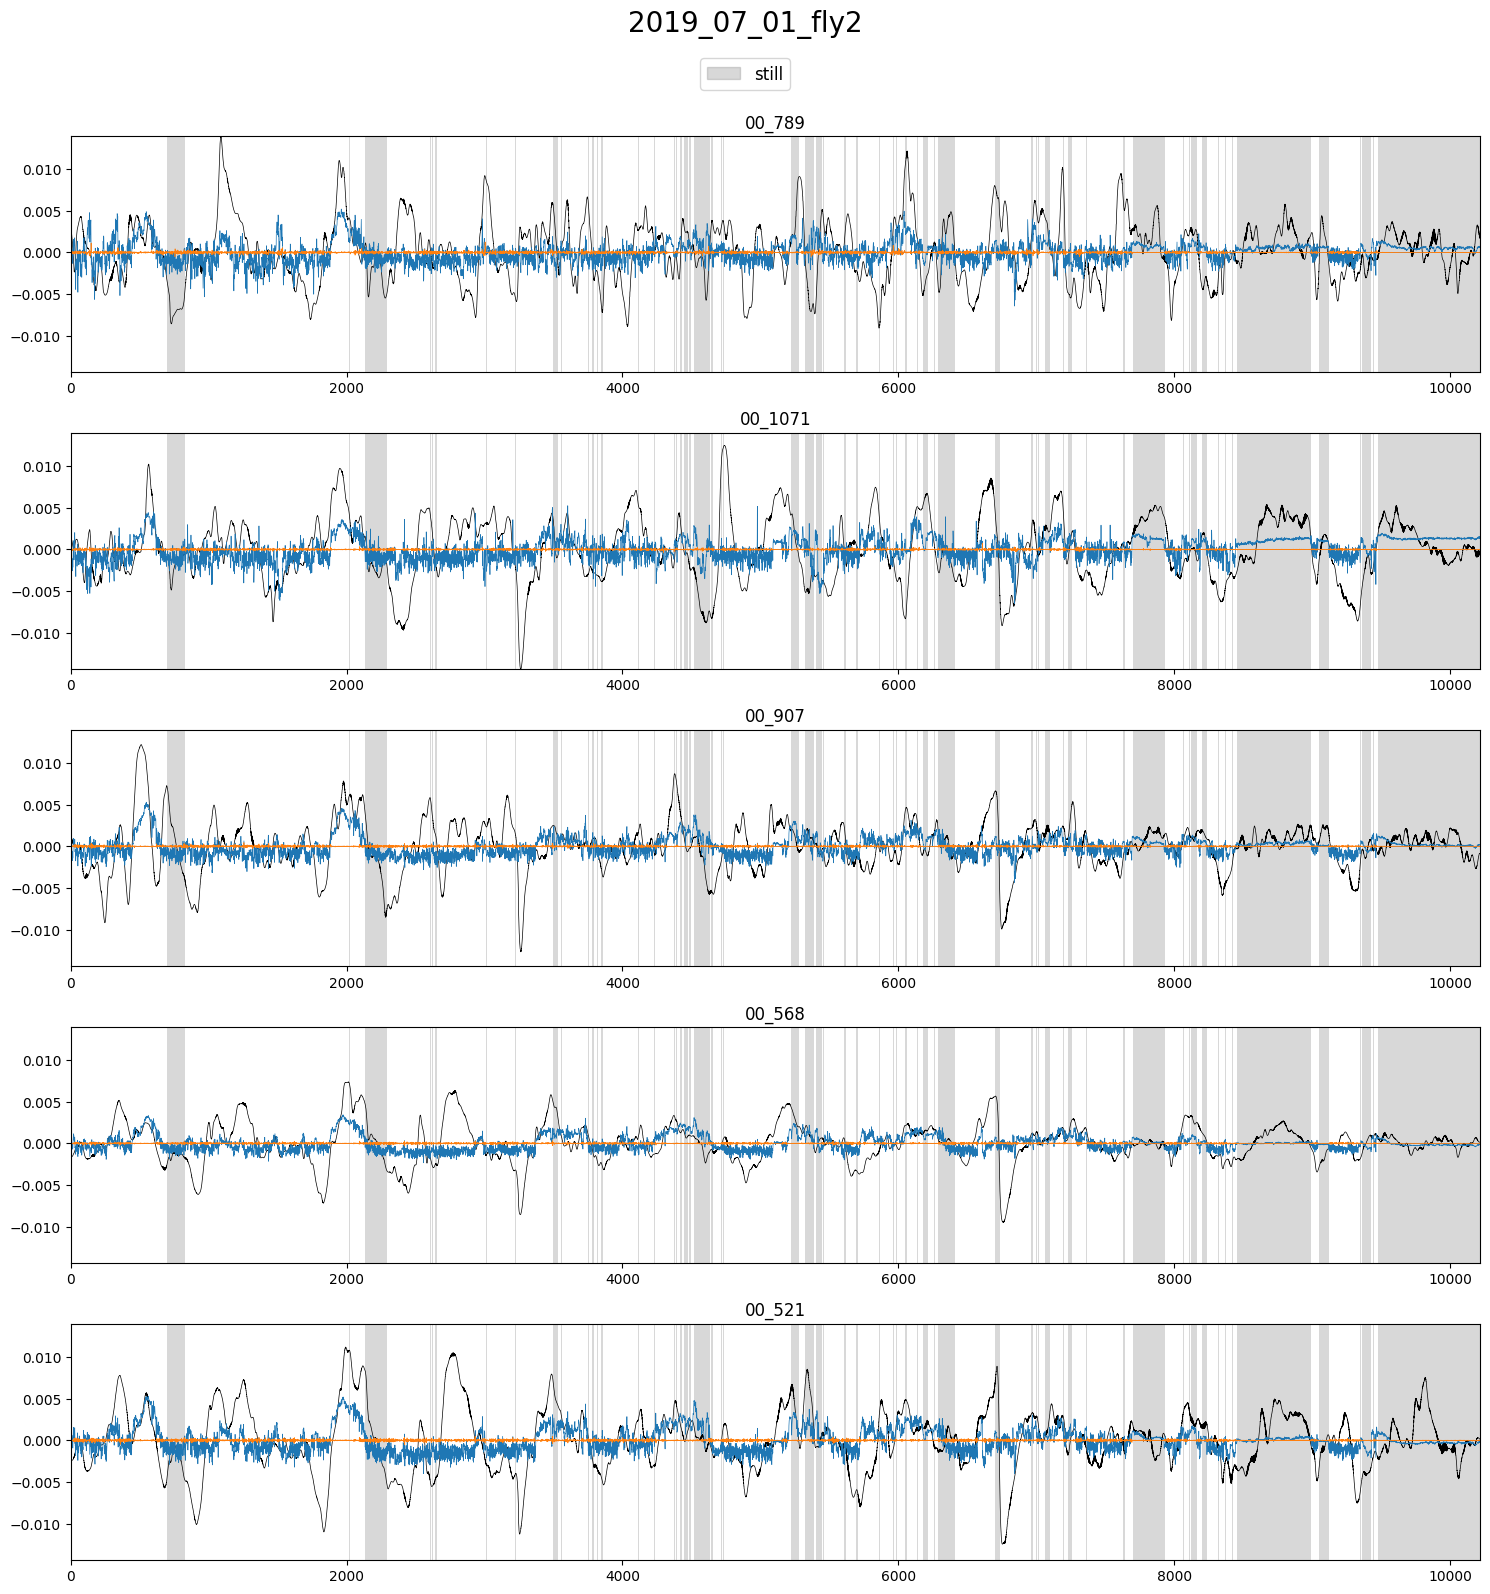

In [64]:
max = traces_residuals[file_ids.index(plot_id)].values.shape[0]
plot_utils.plot_traces(f'{filenames[file_ids.index(plot_id)]}',
					   states[file_ids.index(plot_id)].iloc[:max]['still'].reset_index(drop=True),
					   [traces_residuals[file_ids.index(plot_id)].iloc[:max, r2_indices[0][-5:]].reset_index(drop=True),
					    traces_residuals_pred[0].iloc[:max, r2_indices[0][-5:]].reset_index(drop=True),
					    traces_residuals_pred[1].iloc[:max, r2_indices[0][-5:]].reset_index(drop=True)],
					   plots_per_row=1, top_space=1, ylimits=None)

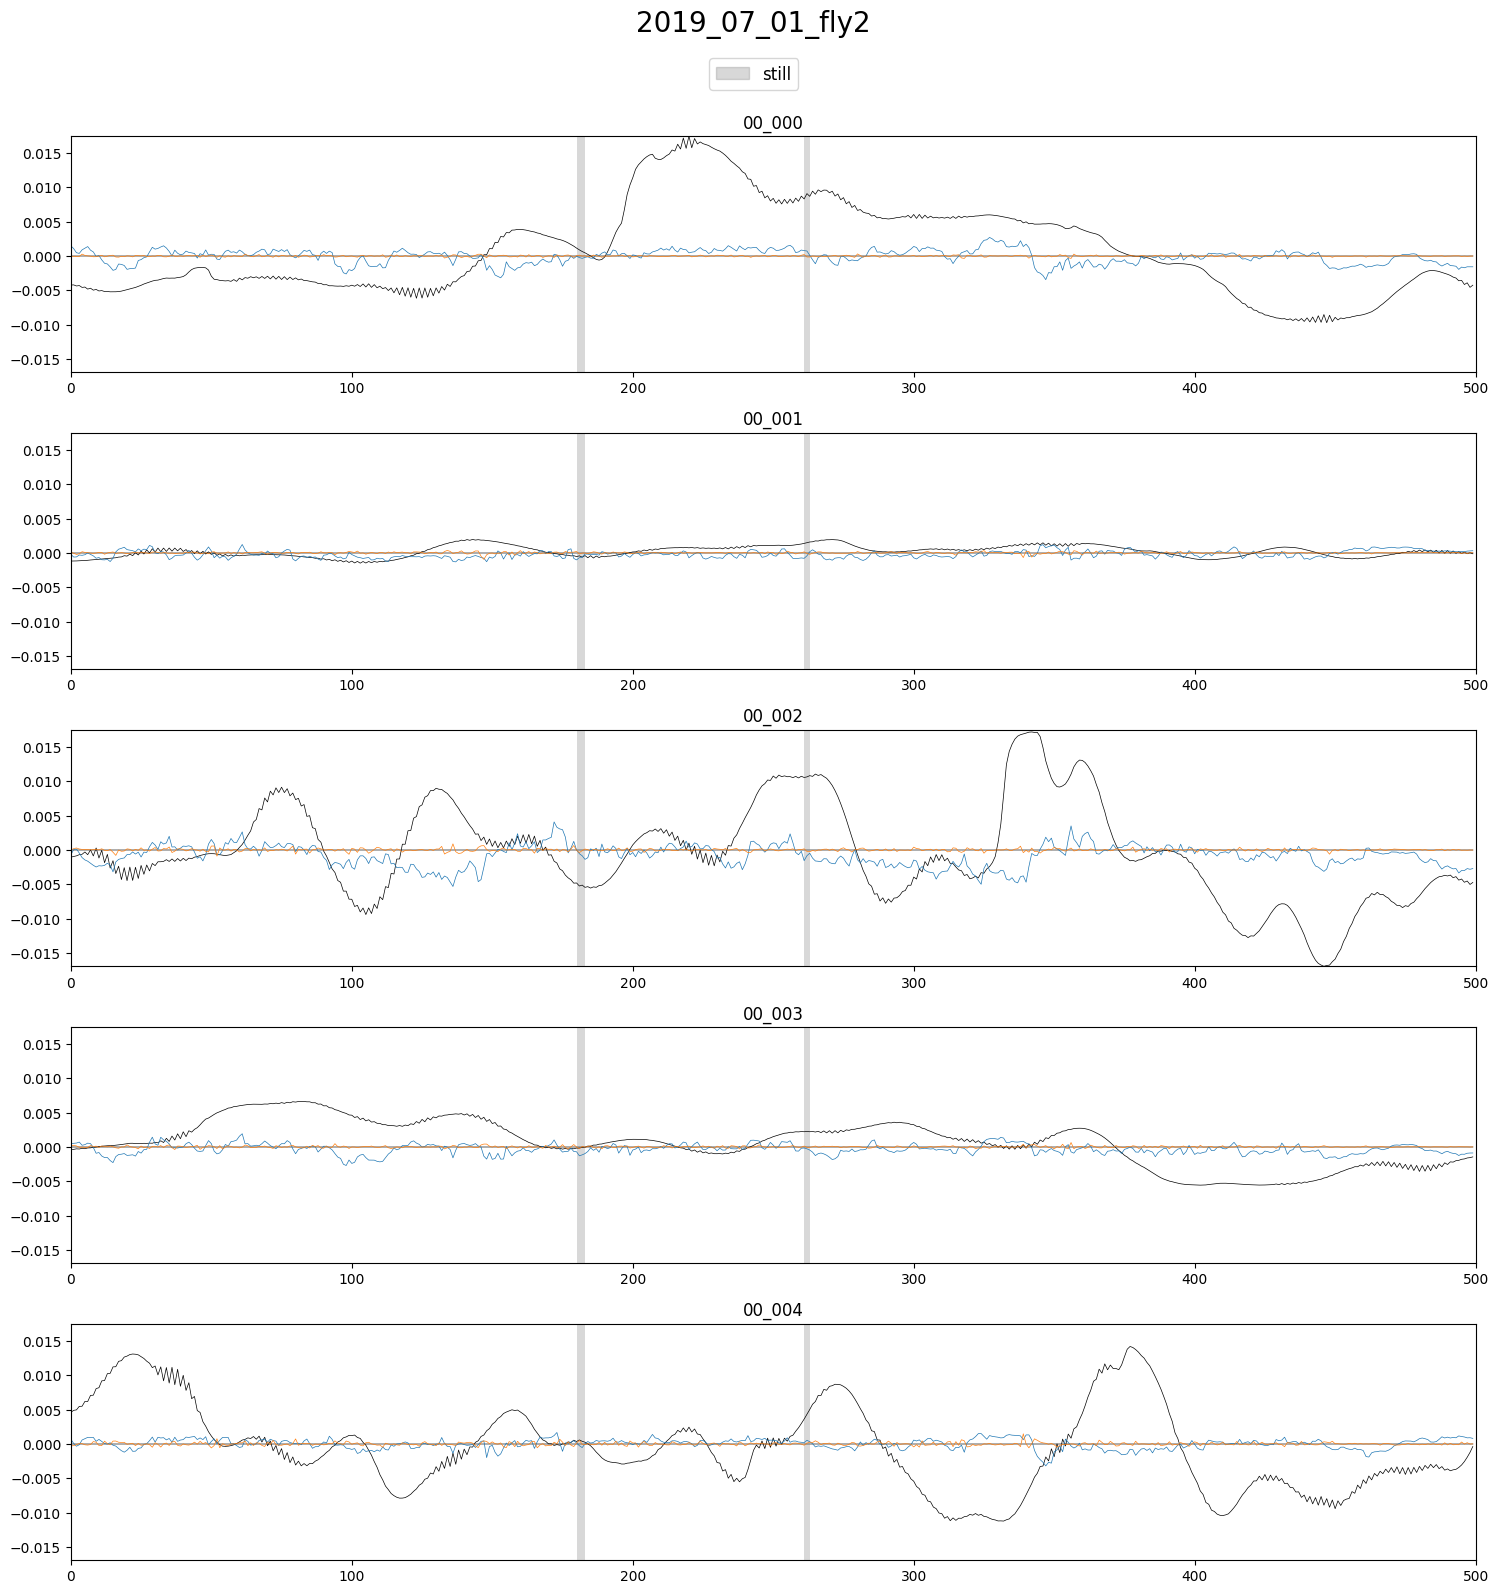

In [20]:
plot_utils.plot_traces(f'{filenames[file_ids.index(plot_id)]}',
					   states[file_ids.index(plot_id)].iloc[:500]['still'].reset_index(drop=True),
					   [traces_residuals[file_ids.index(plot_id)].iloc[:500, :5].reset_index(drop=True),
					    traces_residuals_pred[0].iloc[:500, :5].reset_index(drop=True),
					    traces_residuals_pred[1].iloc[:500, :5].reset_index(drop=True)],
					   plots_per_row=1, top_space=1, ylimits=None)

# CCA

In [59]:
modes_concrete, modes_concrete_b = list(), list()
recos_concrete, recos_concrete_b = list(), list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data

for i, markers_version in enumerate([markers_zs, markers_rel_zs, markers_diff_zs]):
	marker = markers_version[file_ids.index(plot_id)]
	if i != 2:
		marker = marker.iloc[1:]
	trace = traces[file_ids.index(plot_id)]
	trace_residual = traces_residuals[file_ids.index(plot_id)]

	n_ccv = markers_version[file_ids.index(plot_id)].values.shape[1]

	cca = CCA(n_components=n_ccv, scale=True)

	trace_residual_reduced, marker_reduced = cca.fit_transform(trace_residual.values, marker.values)
	trace_residual_reconstructed, marker_reconstructed = cca.inverse_transform(trace_residual_reduced, marker_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	modes_concrete_b.append(pd.DataFrame(data=marker_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)]))
	recos_concrete_b.append(pd.DataFrame(data=marker_reconstructed, columns=marker.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace.values)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual.values)
	vars_expl_con.append([var_ratio])
	vars_expl_con_rs.append([var_ratio_rs])

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/sklearn/cross_decomposition/_pls.py:104: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


In [65]:
for i in range(3):
	corrs = [
		np.corrcoef(modes_concrete[i].values[:, j], modes_concrete_b[i].values[:, j])[0, 1] for j in range(modes_concrete[i].values.shape[1])
	]
	for j, corr in enumerate(corrs):
		print(f'{i}\tCV{j}: {corr:.2f}')

0	CV0: 0.95
0	CV1: 0.93
0	CV2: 0.88
0	CV3: 0.88
0	CV4: 0.85
0	CV5: 0.83
0	CV6: 0.81
0	CV7: 0.81
0	CV8: 0.79
0	CV9: 0.77
0	CV10: 0.75
0	CV11: 0.73
0	CV12: 0.69
0	CV13: 0.64
0	CV14: 0.62
0	CV15: 0.54
1	CV0: 0.95
1	CV1: 0.93
1	CV2: 0.88
1	CV3: 0.88
1	CV4: 0.85
1	CV5: 0.83
1	CV6: 0.81
1	CV7: 0.81
1	CV8: 0.79
1	CV9: 0.77
1	CV10: 0.75
1	CV11: 0.73
1	CV12: 0.69
1	CV13: 0.64
1	CV14: 0.62
1	CV15: 0.54
2	CV0: 0.44
2	CV1: 0.38
2	CV2: 0.36
2	CV3: 0.35
2	CV4: 0.34
2	CV5: 0.33
2	CV6: 0.30
2	CV7: 0.30
2	CV8: 0.30
2	CV9: 0.29
2	CV10: 0.28
2	CV11: 0.28
2	CV12: 0.27
2	CV13: 0.26
2	CV14: 0.25
2	CV15: 0.23


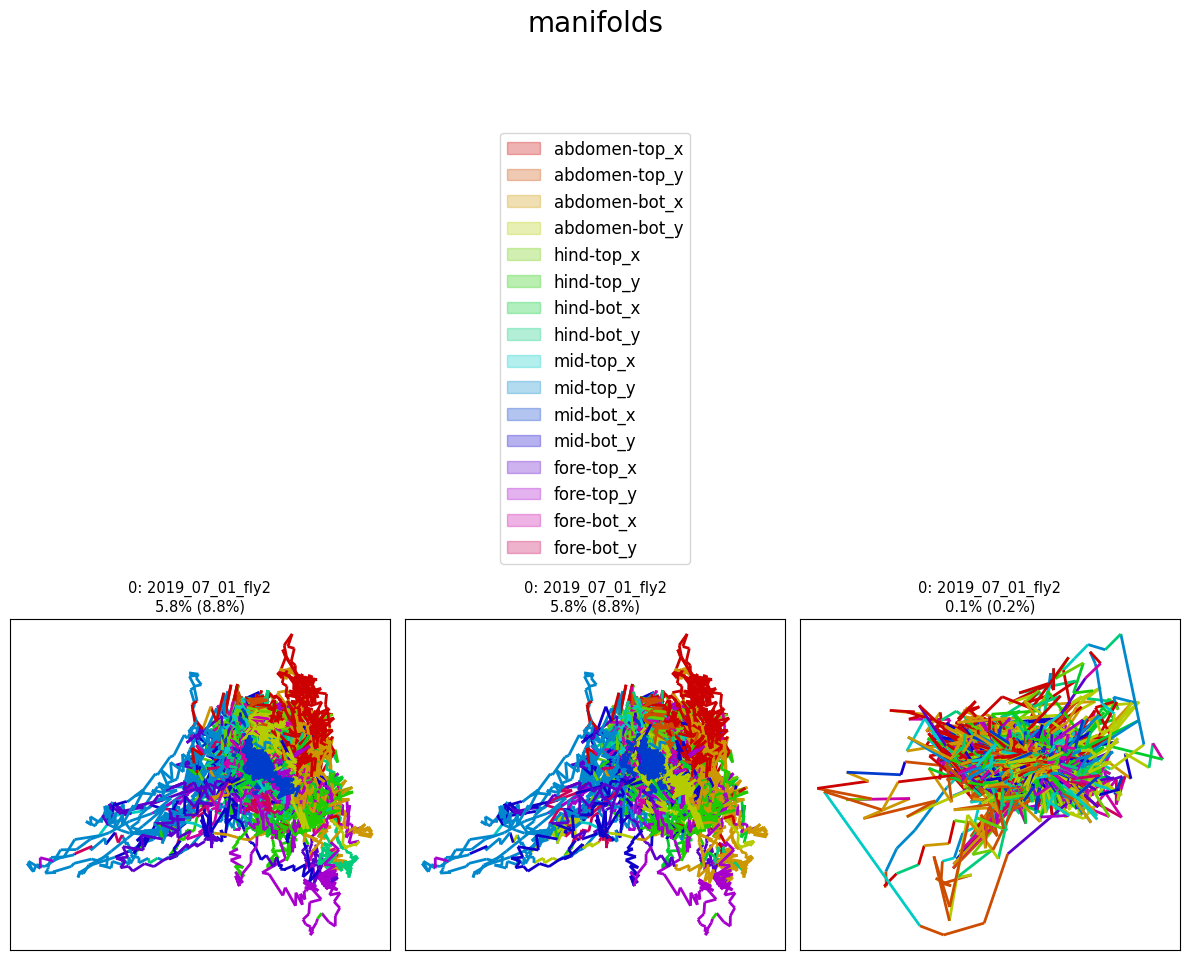

3.9% (5.9%)


In [101]:
plot_utils.plot_manifolds([f'{str(plot_id)}: {filenames[file_ids.index(plot_id)]}'] * 3,
						  [modes_concrete[i] for i in range(3)], [markers[file_ids.index(plot_id)] for markers in [markers_zs, markers_rel_zs, markers_diff_zs]],
						  [vars_expl_con[i][:] for i in range(3)], [vars_expl_con_rs[i][:] for i in range(3)],
						  top_space=6.5)

In [ ]:
# traces_concretes_indices = [np.argsort(xloads_cca_con[:, 0]) for xloads_cca_con in loads_cca_con]
# markers_diff_indices = [np.argsort(yloads_cca_con[:, 0])[::-1] for yloads_cca_con in loads_cca_con_b]
#
# markers_diff_sorted = [ew.iloc[:, ew_idx.tolist()] for ew, ew_idx in zip(markers_diff, markers_diff_indices)]
# traces_concretes_sorted = [t_con.iloc[:, t_con_idx.tolist()] for t_con, t_con_idx in zip(recos_concrete, traces_concretes_indices)]

In [ ]:
# plot_utils.plot_heatmap_stack(traces_concretes_sorted[file_ids.index(plot_id)],
# 							  markers_diff_sorted[file_ids.index(plot_id)],
# 							  'neuronal concrete traces', 'markers',
# 							  height_ratios=(1.5, 4), ylimits_top=(-1, 1))

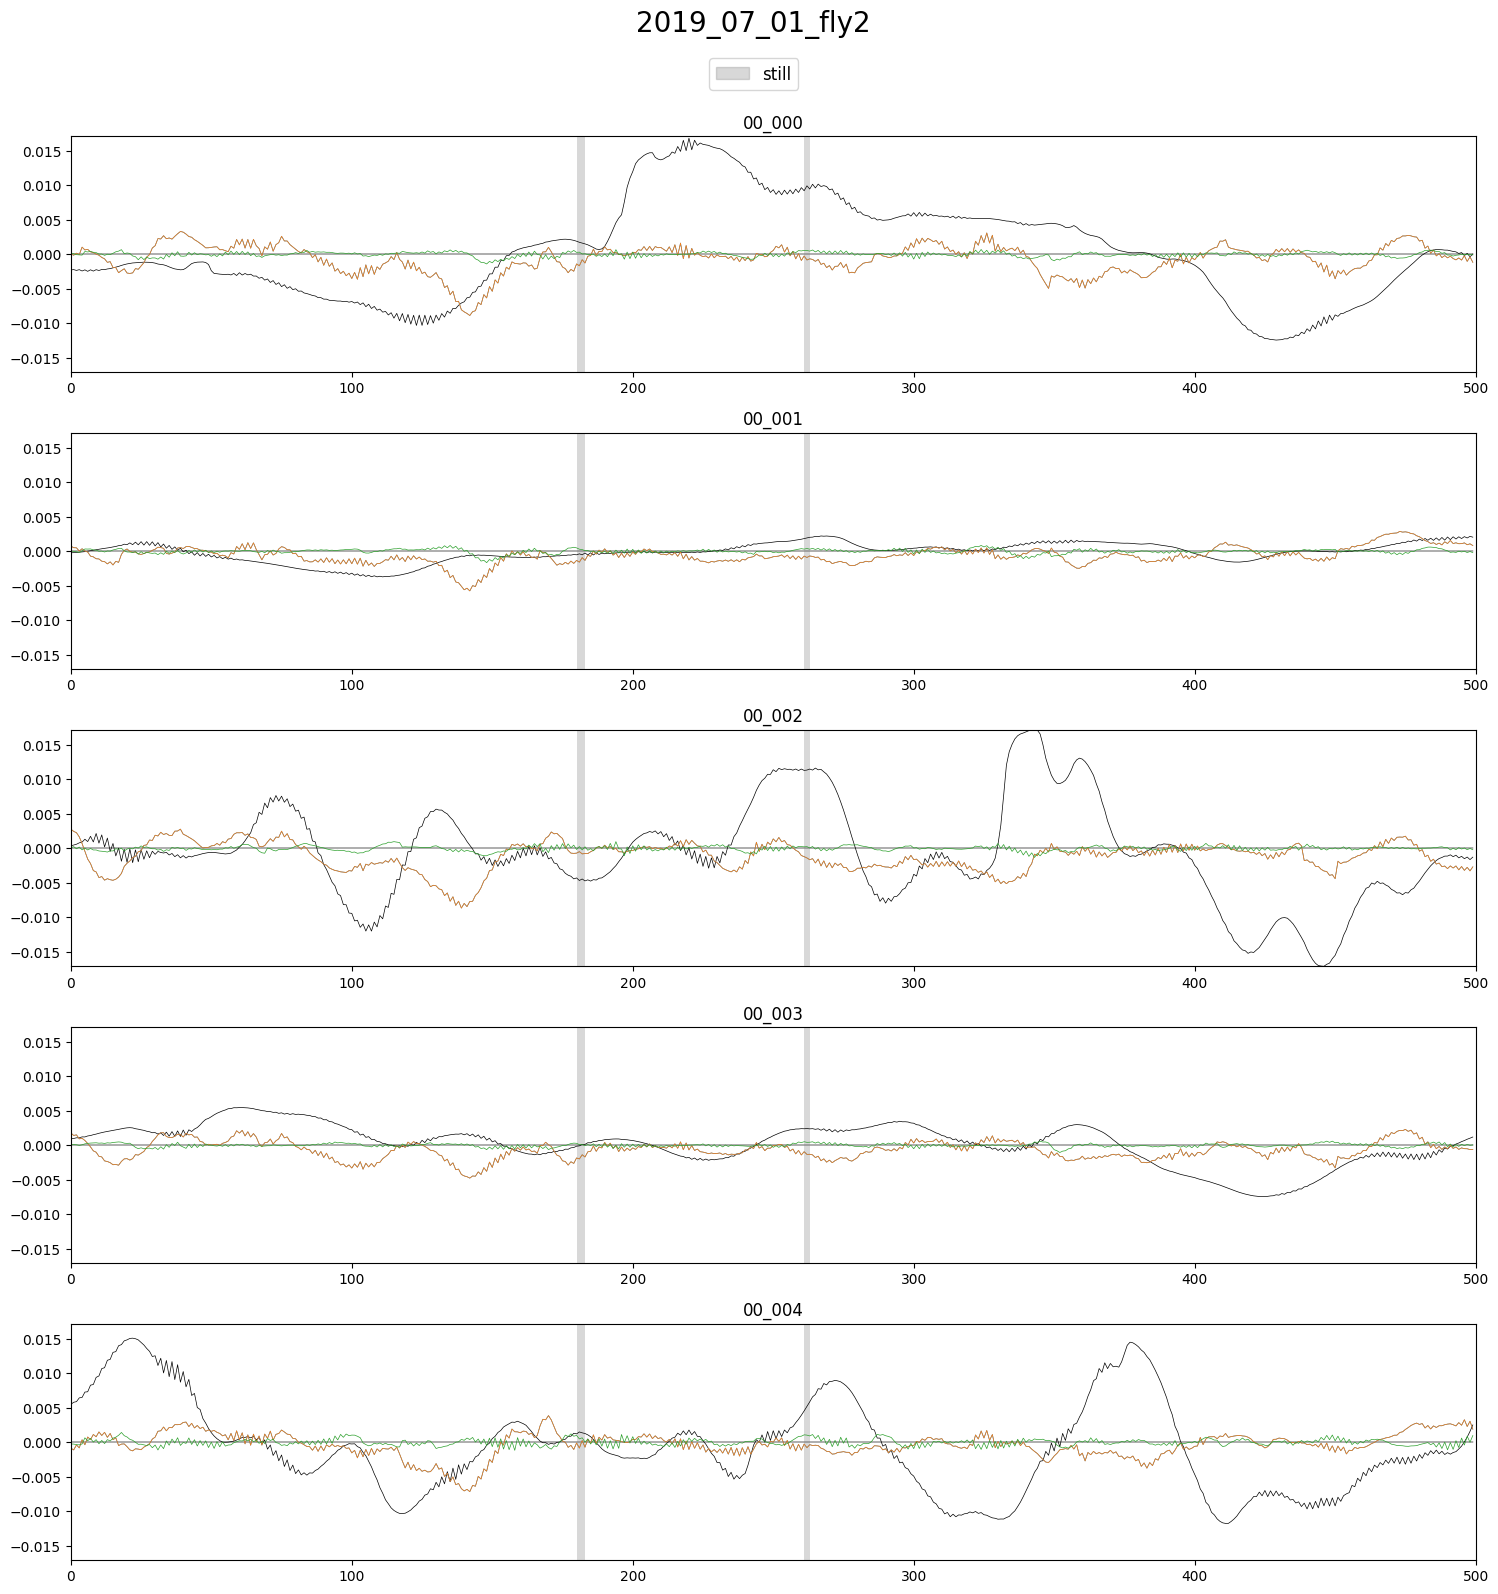

In [96]:
plot_utils.plot_traces(f'{filenames[file_ids.index(plot_id)]}',
					   states[file_ids.index(plot_id)].iloc[:500]['still'].reset_index(drop=True),
					   [traces_residuals[file_ids.index(plot_id)].iloc[:500, :5].reset_index(drop=True),
					    recos_concrete[0].iloc[:500, :5].reset_index(drop=True),
					    recos_concrete[1].iloc[:500, :5].reset_index(drop=True),
					    recos_concrete[2].iloc[:500, :5].reset_index(drop=True)],
					   plots_per_row=1, top_space=1, ylimits=None)

# residual subspace